# K-means 聚类

在本练习中，你将实现 K-means 算法，并用它进行图像压缩。

* 你将从一个示例数据集开始，它将帮助你直观理解 K-means 算法是如何工作的。
* 之后，你将使用 K-means 算法进行图像压缩，方法是把图像中出现的颜色数量减少到只保留该图像中最常见的那些颜色。




# 大纲
- [ 1 - 实现 K-means](#1)
  - [ 1.1 找到最近的质心](#1.1)
    - [ 练习 1](#ex01)
  - [ 1.2 计算质心均值](#1.2)
    - [ 练习 2](#ex02)
- [ 2 - 在示例数据集上运行 K-means ](#2)
- [ 3 - 随机初始化](#3)
- [ 4 - 用 K-means 进行图像压缩](#4)
  - [ 4.1 数据集](#4.1)
  - [ 4.2 在图像像素上运行 K-Means](#4.2)
  - [ 4.3 压缩图像](#4.3)


_**注意：** 为防止自动评分器报错，你不得编辑或删除本实验中不参与评分的单元格。也请不要添加任何新单元格。
**一旦你通过了本次作业** 并想试验任何不参与评分的代码，你可以按照本笔记本底部的说明操作。_

首先，运行下面的单元格来导入本次作业中需要的软件包：

- [numpy](https://numpy.org/) 是用 Python 进行科学计算的基础软件包。
- [matplotlib](http://matplotlib.org) 是 Python 中流行的绘图库。
- `utils.py` 包含本次作业的辅助函数。你不需要修改这个文件中的代码。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *

%matplotlib inline

<a name="1"></a>
## 1 - 实现 K-means

K-means 算法是一种自动把相似的数据点聚到一起的方法。

* 具体来说，给定一个训练集 $\{x^{(1)}, ..., x^{(m)}\}$，你想把这些数据分组成若干个内聚的"簇"（clusters）


* K-means 是一个迭代过程，它
     * 从猜测初始质心开始，然后
     * 通过以下步骤来精化这个猜测
         * 反复地把样本分配到它们最近的质心，然后
         * 基于这些分配重新计算质心。


* 用伪代码表示，K-means 算法如下：

    ``` python
    # Initialize centroids
    # K is the number of clusters
    centroids = kMeans_init_centroids(X, K)
    
    for iter in range(iterations):
        # Cluster assignment step: 
        # Assign each data point to the closest centroid. 
        # idx[i] corresponds to the index of the centroid 
        # assigned to example i
        idx = find_closest_centroids(X, centroids)

        # Move centroid step: 
        # Compute means based on centroid assignments
        centroids = compute_centroids(X, idx, K)
    ```


* 该算法的内循环反复执行两个步骤：
    1. 把每个训练样本 $x^{(i)}$ 分配到它最近的质心，以及
    2. 使用分配给每个质心的点重新计算该质心的均值。


* $K$-means 算法总会收敛到质心的某个最终均值集合。

* 然而，收敛到的解不一定总是理想的，并且取决于质心的初始设置。
    * 因此在实践中，K-means 算法通常会用不同的随机初始化运行几次。
    * 在这些来自不同随机初始化的解之间做选择的一种方法，是选择代价函数值（畸变，distortion）最低的那个。

你将在接下来的小节中分别实现 K-means 算法的两个阶段。
* 你将从完成 `find_closest_centroid` 开始，然后继续完成 `compute_centroids`。

<a name="1.1"></a>
### 1.1 找到最近的质心

在 K-means 算法的"簇分配"阶段，算法在给定质心当前位置的情况下，把每个训练样本 $x^{(i)}$ 分配到它最近的质心。

<a name="ex01"></a>
### 练习 1

你的任务是完成 `find_closest_centroids` 中的代码。
* 这个函数接收数据矩阵 `X` 以及 `centroids` 中所有质心的位置
* 它应输出一个一维数组 `idx`（其元素数量与 `X` 相同），保存每个训练样本最近的质心的索引（一个取值于 $\{0,...,K-1\}$ 中的值，其中 $K$ 是质心的总数）。*（注意：索引范围 0 到 K-1 与课程中所示的（即 1 到 K）略有不同，因为 Python 列表索引从 0 而不是 1 开始）*
* 具体来说，对每个样本 $x^{(i)}$ 我们设
$$c^{(i)} := j \quad \mathrm{that \; minimizes} \quad ||x^{(i)} - \mu_j||^2,$$
其中
 * $c^{(i)}$ 是离 $x^{(i)}$ 最近的质心的索引（对应起始代码中的 `idx[i]`），且
 * $\mu_j$ 是第 $j$ 个质心的位置（值）。（存储在起始代码的 `centroids` 中）
 * $||x^{(i)} - \mu_j||$ 是 L2 范数

如果你卡住了，可以查看下面单元格之后给出的提示，以帮助你完成实现。

In [ ]:
# UNQ_C1
# GRADED FUNCTION: find_closest_centroids

def find_closest_centroids(X, centroids):
    """
    Computes the centroid memberships for every example
    
    Args:
        X (ndarray): (m, n) Input values      
        centroids (ndarray): (K, n) centroids
    
    Returns:
        idx (array_like): (m,) closest centroids
    
    """

    # Set K
    K = centroids.shape[0]

    # You need to return the following variables correctly
    idx = np.zeros(X.shape[0], dtype=int)

    ### START CODE HERE ###
    for i in range(X.shape[0]):
        # Array to hold distance between X[i] and each centroids[j]
        distance = [] 
        for j in range(centroids.shape[0]):
            norm_ij = np.linalg.norm(X[i , :] - centroids[j , :], ord=2)
            distance.append(norm_ij)

        idx[i] = np.argmin(distance)
        
             
        
     ### END CODE HERE ###
    
    return idx

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
    
* 下面是你可以用来组织这个函数整体实现的方式

```python 
def find_closest_centroids(X, centroids):

    # Set K
    K = centroids.shape[0]

    # You need to return the following variables correctly
    idx = np.zeros(X.shape[0], dtype=int)

    ### START CODE HERE ###
    for i in range(X.shape[0]):
        # Array to hold distance between X[i] and each centroids[j]
        distance = [] 
        for j in range(centroids.shape[0]):
            norm_ij = # Your code to calculate the norm between (X[i] - centroids[j])
            distance.append(norm_ij)

        idx[i] = # Your code here to calculate index of minimum value in distance
    ### END CODE HERE ###
    return idx
```

* 如果你仍然卡住，可以查看下面给出的提示，弄清如何计算 `norm_ij` 和 `idx[i]`。
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 norm_ij 的提示</b></font></summary>
           &emsp; &emsp; 你可以使用 <a href="https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html">np.linalg.norm</a> 来计算范数
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 norm_ij 的更多提示</b></font></summary>
               &emsp; &emsp; 你可以这样计算 norm_ij：<code>norm_ij = np.linalg.norm(X[i] - centroids[j]) </code>
           </details>
    </details>

    <details>
          <summary><font size="2" color="darkblue"><b>计算 idx[i] 的提示</b></font></summary>
          &emsp; &emsp; 你可以使用 <a href="https://numpy.org/doc/stable/reference/generated/numpy.argmin.html">np.argmin</a> 来找到最小值的索引
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 idx[i] 的更多提示</b></font></summary>
              &emsp; &emsp; 你可以这样计算 idx[i]：<code>idx[i] = np.argmin(distance)</code>
          </details>
    </details>
        
    </details>

</details>

    

现在让我们用一个示例数据集来检查你的实现

In [3]:
# Load an example dataset that we will be using
X = load_data()

下面的代码打印变量 `X` 中的前五个元素以及该变量的维度

In [4]:
print("First five elements of X are:\n", X[:5]) 
print('The shape of X is:', X.shape)

First five elements of X are:
 [[1.84207953 4.6075716 ]
 [5.65858312 4.79996405]
 [6.35257892 3.2908545 ]
 [2.90401653 4.61220411]
 [3.23197916 4.93989405]]
The shape of X is: (300, 2)


In [5]:
# Select an initial set of centroids (3 Centroids)
initial_centroids = np.array([[3,3], [6,2], [8,5]])

# Find closest centroids using initial_centroids
idx = find_closest_centroids(X, initial_centroids)

# Print closest centroids for the first three elements
print("First three elements in idx are:", idx[:3])

# UNIT TEST
from public_tests import *

find_closest_centroids_test(find_closest_centroids)

First three elements in idx are: [0 2 1]
All tests passed!


**预期输出**：
<table>
  <tr>
    <td> <b>idx 中的前三个元素为<b></td>
    <td> [0 2 1] </td> 
  </tr>
</table>

<a name="1.2"></a>
### 1.2 计算质心均值

在给定每个点到某个质心的分配之后，算法的第二阶段为每个质心重新计算被分配给它的那些点的均值。


<a name="ex02"></a>
### 练习 2

请完成下面的 `compute_centroids`，以重新计算每个质心的值

* 具体来说，对每个质心 $\mu_k$ 我们设
$$\mu_k = \frac{1}{|C_k|} \sum_{i \in C_k} x^{(i)}$$

    其中
    * $C_k$ 是被分配到质心 $k$ 的样本集合
    * $|C_k|$ 是集合 $C_k$ 中样本的数量


* 具体地，如果两个样本（比如 $x^{(3)}$ 和 $x^{(5)}$）被分配到质心 $k=2$，那么你应该更新 $\mu_2 = \frac{1}{2}(x^{(3)}+x^{(5)})$。

如果你卡住了，可以查看下面单元格之后给出的提示，以帮助你完成实现。

In [ ]:
# UNQ_C2
# GRADED FUNCTION: compute_centroids

def compute_centroids(X, idx, K):
    """
    Returns the new centroids by computing the means of the 
    data points assigned to each centroid.
    
    Args:
        X (ndarray):   (m, n) Data points
        idx (ndarray): (m,) Array containing index of closest centroid for each 
                       example in X. Concretely, idx[i] contains the index of 
                       the centroid closest to example i
        K (int):       number of centroids
    
    Returns:
        centroids (ndarray): (K, n) New centroids computed
    """
    
    # Useful variables
    m, n = X.shape
    
    # You need to return the following variables correctly
    centroids = np.zeros((K, n))
    
    ### START CODE HERE ###
    for j in range(K):
        points = X[idx == j]
        centroids[j] = np.mean(points, axis=0)
              
        
    ### END CODE HERE ## 
    
    return centroids

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
    
* 下面是你可以用来组织这个函数整体实现的方式
    ```python 
    def compute_centroids(X, idx, K):
        # Useful variables
        m, n = X.shape
    
        # You need to return the following variables correctly
        centroids = np.zeros((K, n))
    
        ### START CODE HERE ###
        for k in range(K):   
            points = # Your code here to get a list of all data points in X assigned to centroid k  
            centroids[k] = # Your code here to compute the mean of the points assigned
    ### END CODE HERE ## 
    
    return centroids
    ```
  
    如果你仍然卡住，可以查看下面给出的提示，弄清如何计算 `points` 和 `centroids[k]`。
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 points 的提示</b></font></summary>
           &emsp; &emsp; 假设我们想找到 X 中被分配到簇 <code>k=0</code> 的所有值。也就是说，这些样本在 idx 中对应的值是 0。在 Python 中，我们可以这样做：<code>X[idx == 0]</code>。类似地，被分配到质心 <code>k=1</code> 的点是 <code>X[idx == 1]</code>
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 points 的更多提示</b></font></summary>
               &emsp; &emsp; 你可以这样计算 points：<code>points = X[idx == k] </code>
           </details>
    </details>

     <details>
          <summary><font size="2" color="darkblue"><b>计算 centroids[k] 的提示</b></font></summary>
          &emsp; &emsp; 你可以使用 <a href="https://numpy.org/doc/stable/reference/generated/numpy.mean.html">np.mean</a> 来求均值。务必设置参数 <code>axis=0</code>
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 centroids[k] 的更多提示</b></font></summary>
              &emsp; &emsp; 你可以这样计算 centroids[k]：<code>centroids[k] = np.mean(points, axis = 0)</code>
          </details>
    </details>
        
    </details>

</details>

    

现在通过运行下面的单元格来检查你的实现

In [7]:
K = 3
centroids = compute_centroids(X, idx, K)

print("The centroids are:", centroids)

# UNIT TEST
compute_centroids_test(compute_centroids)

The centroids are: [[2.42830111 3.15792418]
 [5.81350331 2.63365645]
 [7.11938687 3.6166844 ]]
All tests passed!


**预期输出**：

2.42830111 3.15792418

5.81350331 2.63365645

7.11938687 3.6166844 

<a name="2"></a>
## 2 - 在示例数据集上运行 K-means

在你完成上面的两个函数（`find_closest_centroids` 和 `compute_centroids`）之后，下一步是在一个玩具二维数据集上运行 K-means 算法，以帮助你理解 K-means 是如何工作的。
* 我们鼓励你看看下面的函数（`run_kMeans`），以理解它是如何工作的。
* 请注意，这段代码在一个循环中调用你实现的两个函数。

当你运行下面的代码时，它会产生一个可视化，逐步展示算法在每次迭代时的进展。
* 最后，你的图应该看起来像图 1 中显示的那样。
* 最终的质心是彩色簇中间的黑色 X 标记。
* 你可以通过查看与它相连的其他 X 标记，来了解这些质心是如何到达它们的最终位置的。

<img src="images/figure 1.png" width="500" height="500">


**注意**：这部分你不需要实现任何东西。只需运行下面提供的代码

In [8]:
# You do not need to implement anything for this part

def run_kMeans(X, initial_centroids, max_iters=10, plot_progress=False):
    """
    Runs the K-Means algorithm on data matrix X, where each row of X
    is a single example
    """
    
    # Initialize values
    m, n = X.shape
    K = initial_centroids.shape[0]
    centroids = initial_centroids
    previous_centroids = centroids    
    idx = np.zeros(m)
    plt.figure(figsize=(8, 6))

    # Run K-Means
    for i in range(max_iters):
        
        #Output progress
        print("K-Means iteration %d/%d" % (i, max_iters-1))
        
        # For each example in X, assign it to the closest centroid
        idx = find_closest_centroids(X, centroids)
        
        # Optionally plot progress
        if plot_progress:
            plot_progress_kMeans(X, centroids, previous_centroids, idx, K, i)
            previous_centroids = centroids
            
        # Given the memberships, compute new centroids
        centroids = compute_centroids(X, idx, K)
    plt.show() 
    return centroids, idx

K-Means iteration 0/9
K-Means iteration 1/9
K-Means iteration 2/9
K-Means iteration 3/9
K-Means iteration 4/9
K-Means iteration 5/9
K-Means iteration 6/9
K-Means iteration 7/9
K-Means iteration 8/9
K-Means iteration 9/9


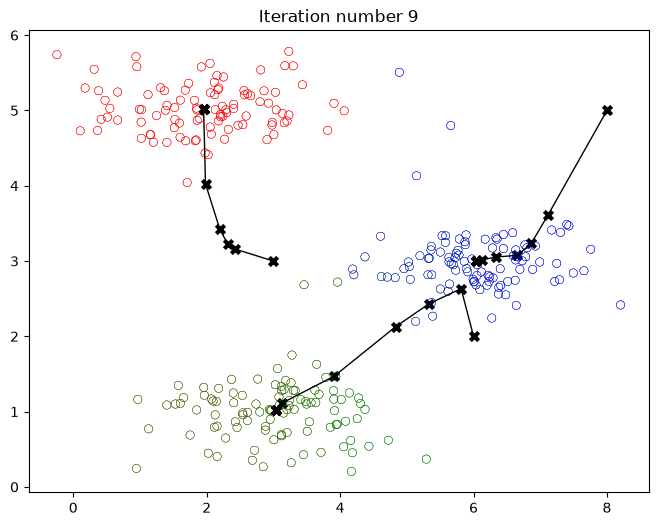

In [9]:
# Load an example dataset
X = load_data()

# Set initial centroids
initial_centroids = np.array([[3,3],[6,2],[8,5]])

# Number of iterations
max_iters = 10

# Run K-Means
centroids, idx = run_kMeans(X, initial_centroids, max_iters, plot_progress=True)

<a name="3"></a>
## 3 - 随机初始化

对示例数据集而言，质心的初始分配被设计成让你会看到与图 1 相同的图。在实践中，初始化质心的一个好策略是从训练集中随机选择样本。

在本练习的这一部分，你应理解函数 `kMeans_init_centroids` 是如何实现的。
* 代码首先随机打乱样本的索引（使用 `np.random.permutation()`）。
* 然后，它基于索引的随机排列选择前 $K$ 个样本。
* 这使得样本可以被随机选择，而没有两次选中同一个样本的风险。

**注意**：本练习的这一部分你不需要实现任何东西。

In [10]:
# You do not need to modify this part

def kMeans_init_centroids(X, K):
    """
    This function initializes K centroids that are to be 
    used in K-Means on the dataset X
    
    Args:
        X (ndarray): Data points 
        K (int):     number of centroids/clusters
    
    Returns:
        centroids (ndarray): Initialized centroids
    """
    
    # Randomly reorder the indices of examples
    randidx = np.random.permutation(X.shape[0])
    
    # Take the first K examples as centroids
    centroids = X[randidx[:K]]
    
    return centroids

你可以再次运行 K-Means，但这次使用随机的初始质心。多次运行下面的单元格，观察基于所选初始点如何创建出不同的簇。

K-Means iteration 0/9
K-Means iteration 1/9
K-Means iteration 2/9
K-Means iteration 3/9
K-Means iteration 4/9
K-Means iteration 5/9
K-Means iteration 6/9
K-Means iteration 7/9
K-Means iteration 8/9
K-Means iteration 9/9


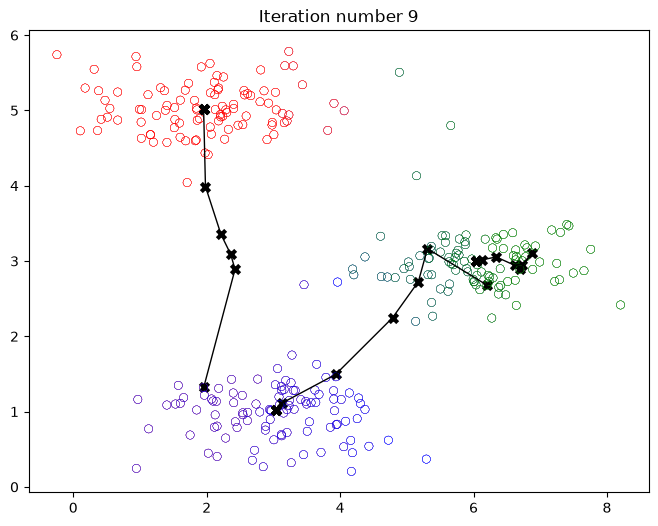

In [11]:
# Run this cell repeatedly to see different outcomes.

# Set number of centroids and max number of iterations
K = 3
max_iters = 10

# Set initial centroids by picking random examples from the dataset
initial_centroids = kMeans_init_centroids(X, K)

# Run K-Means
centroids, idx = run_kMeans(X, initial_centroids, max_iters, plot_progress=True)

<a name="4"></a>
## 4 - 用 K-means 进行图像压缩

在本练习中，你将把 K-means 应用于图像压缩。

* 在图像$^{2}$的一种直接的 24 位颜色表示中，每个像素被表示为三个 8 位无符号整数（范围从 0 到 255），它们指定红、绿、蓝的强度值。这种编码通常被称为 RGB 编码。
* 我们的图像包含数千种颜色，在本练习的这一部分，你将把颜色数量减少到 16 种颜色。
* 通过做这样的缩减，就可以用一种高效的方式来表示（压缩）这张照片。
* 具体来说，你只需要存储所选 16 种颜色的 RGB 值，并且对图像中的每个像素，你现在只需要存储该位置处颜色的索引（表示 16 种可能性只需要 4 位）。

在这一部分，你将使用 K-means 算法来选出将用于表示压缩图像的 16 种颜色。
* 具体来说，你将把原始图像中的每个像素当作一个数据样本，并使用 K-means 算法找出在三维 RGB 空间中最能把像素分组（聚类）的 16 种颜色。
* 一旦你在图像上计算出了簇质心，你就将用这 16 种颜色来替换原始图像中的像素。

<img src="images/figure 2.png" width="500" height="500">

$^{2}$<sub>本练习中提供的照片属于 Frank Wouters，并经其许可使用。</sub>

<a name="4.1"></a>
### 4.1 数据集

**加载图像**

首先，你将使用 `matplotlib` 来读入原始图像，如下所示。

In [12]:
# Load an image of a bird
original_img = plt.imread('bird_small.png')

**可视化图像**

你可以用下面的代码可视化刚刚加载的图像。

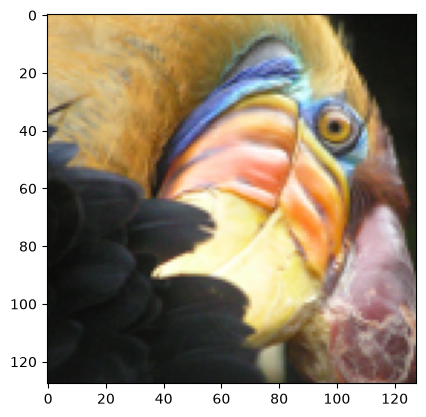

In [13]:
# Visualizing the image
plt.imshow(original_img)

**检查变量的维度**

像往常一样，你将打印出变量的形状，以进一步熟悉数据。

In [ ]:
print("Shape of original_img is:", original_img.shape)
print(np.shape(original_img[0, 0])) # shape of RGB
print(original_img[0, 0])

Shape of original_img is: (128, 128, 3)
(3,)
[0.85882354 0.7058824  0.40392157]


正如你所看到的，这创建了一个三维矩阵 `original_img`，其中
* 前两个索引标识一个像素位置，且
* 第三个索引表示红、绿或蓝。

例如，`original_img[50, 33, 2]` 给出第 50 行第 33 列处像素的蓝色强度。

#### 处理数据

要调用 `run_kMeans`，你需要先把矩阵 `original_img` 变换成一个二维矩阵。

* 下面的代码重塑矩阵 `original_img`，以创建一个 $m \times 3$ 的像素颜色矩阵（其中 $m=16384 = 128\times128$）

*注意：如果你以后在一个 JPG 文件上尝试这个练习，你需要先把像素值除以 255，使它落在 0 到 1 的范围内。这对 PNG 文件（例如 `bird_small.png`）来说不是必需的，因为它已经以所需的范围加载（如 [plt.imread() 文档](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imread.html) 中所述）。我们在下面为此注释了一行，所以你以后如果想尝试不同的文件，只需取消注释即可。*

In [15]:
# Divide by 255 so that all values are in the range 0 - 1 (not needed for PNG files)
# original_img = original_img / 255

# Reshape the image into an m x 3 matrix where m = number of pixels
# (in this case m = 128 x 128 = 16384)
# Each row will contain the Red, Green and Blue pixel values
# This gives us our dataset matrix X_img that we will use K-Means on.

X_img = np.reshape(original_img, (original_img.shape[0] * original_img.shape[1], 3))

<a name="4.2"></a>
### 4.2 在图像像素上运行 K-Means

现在，运行下面的单元格，在预处理后的图像上运行 K-Means。

In [16]:
# Run your K-Means algorithm on this data
# You should try different values of K and max_iters here
K = 50
max_iters = 20

# Using the function you have implemented above. 
initial_centroids = kMeans_init_centroids(X_img, K)

# Run K-Means - this can take a couple of minutes depending on K and max_iters
centroids, idx = run_kMeans(X_img, initial_centroids, max_iters)

K-Means iteration 0/19
K-Means iteration 1/19
K-Means iteration 2/19
K-Means iteration 3/19
K-Means iteration 4/19
K-Means iteration 5/19
K-Means iteration 6/19
K-Means iteration 7/19
K-Means iteration 8/19
K-Means iteration 9/19
K-Means iteration 10/19
K-Means iteration 11/19
K-Means iteration 12/19
K-Means iteration 13/19
K-Means iteration 14/19
K-Means iteration 15/19
K-Means iteration 16/19
K-Means iteration 17/19
K-Means iteration 18/19
K-Means iteration 19/19


<Figure size 800x600 with 0 Axes>

In [17]:
print("Shape of idx:", idx.shape)
print("Closest centroid for the first five elements:", idx[:5])

Shape of idx: (16384,)
Closest centroid for the first five elements: [40 20 20 40 40]


下面的代码将绘制原始图像中找到的所有颜色。如前所述，每个像素的颜色由 RGB 值表示，所以这个图应有 3 个坐标轴——R、G 和 B。你会注意到下面有很多点，代表原始图像中的数千种颜色。红色标记代表运行 K-means 之后的质心。这些将是你用来压缩图像的 16 种颜色。

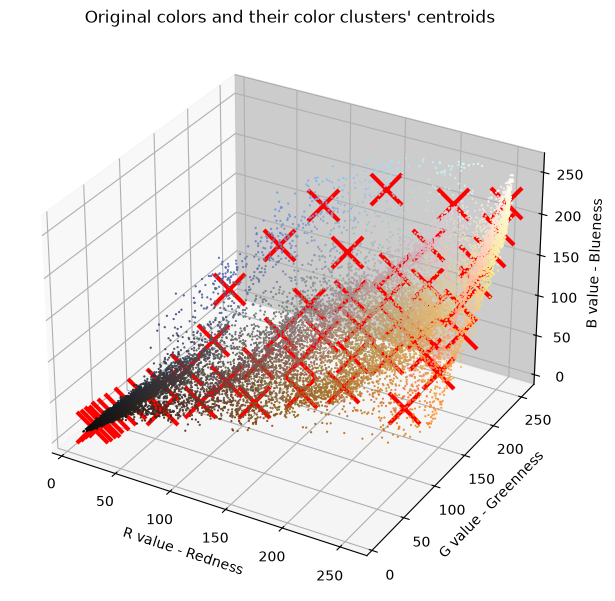

In [18]:
# Plot the colors of the image and mark the centroids
plot_kMeans_RGB(X_img, centroids, idx, K)

你可以用下面的函数可视化上面每个红色标记（即质心）处的颜色。你只有在下一节生成新图像时才会看到这些颜色。每种颜色下方的数字是它的索引，这些就是你在 `idx` 数组中看到的数字。

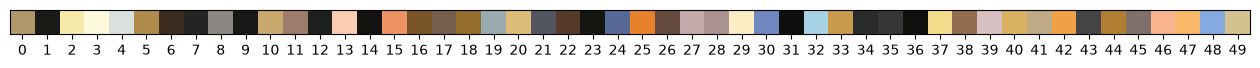

In [19]:
# Visualize the 16 colors selected
show_centroid_colors(centroids)

<a name="4.3"></a>
### 4.3 压缩图像


在找到用来表示图像的前 $K=16$ 种颜色之后，你现在可以使用 `find_closest_centroids` 函数把每个像素位置分配到它最近的质心。
* 这让你能够用每个像素的质心分配来表示原始图像。
* 请注意，你已经显著减少了描述该图像所需的位数。
    * 原始图像对 $128\times128$ 个像素位置中的每一个都需要 24 位（即 RGB 编码中 8 位 x 3 个通道），导致总大小为 $128 \times 128 \times 24 = 393,216$ 位。
    * 新的表示需要一个 16 种颜色的字典形式的额外开销存储，其中每种颜色需要 24 位，但图像本身随后每个像素位置只需要 4 位。
    * 因此所使用的最终位数是 $16 \times 24 + 128 \times 128 \times 4 = 65,920$ 位，这对应于把原始图像压缩了大约 6 倍。

In [20]:
# Find the closest centroid of each pixel
idx = find_closest_centroids(X_img, centroids)

# Replace each pixel with the color of the closest centroid
X_recovered = centroids[idx, :] 

# Reshape image into proper dimensions
X_recovered = np.reshape(X_recovered, original_img.shape) 

最后，你可以通过仅基于质心分配来重建图像，从而查看压缩的效果。
* 具体来说，你用分配给每个像素的质心的值替换了该像素。
* 图 3 展示了一个重建示例。即使得到的图像保留了原始图像的大部分特征，你也会看到一些压缩伪影，因为使用的颜色更少了。

<img src="images/figure 3.png" width="700" height="700">

* 运行下面的代码，看看图像是如何使用先前选出的 16 种颜色重建的。

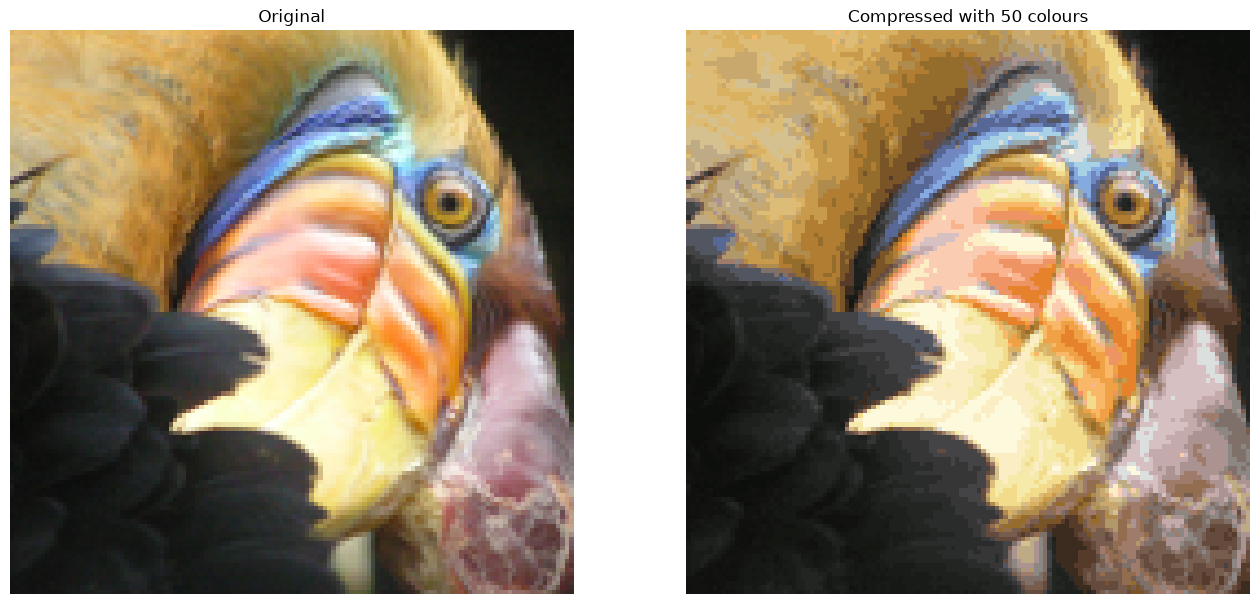

In [21]:
# Display original image
fig, ax = plt.subplots(1,2, figsize=(16,16))
plt.axis('off')

ax[0].imshow(original_img)
ax[0].set_title('Original')
ax[0].set_axis_off()


# Display compressed image
ax[1].imshow(X_recovered)
ax[1].set_title('Compressed with %d colours'%K)
ax[1].set_axis_off()

**恭喜你完成这个关于 K-means 聚类的实验！在下一课中，你将学习无监督学习的另一个应用场景：异常检测。到时候见！**

<details>
  <summary><font size="2" color="darkgreen"><b>如果你想试验任何不参与评分的代码，请点击这里。</b></font></summary>
    <p><i><b>重要提示：请仅在你已经通过本次作业之后再这样做，以避免自动评分器出现问题。</b></i>
    <ol>
        <li> 在笔记本的菜单上，点击 "View" > "Cell Toolbar" > "Edit Metadata"</li>
        <li> 点击你想锁定/解锁的代码单元格旁边的 "Edit Metadata" 按钮</li>
        <li> 把 "editable" 的属性值设为：
            <ul>
                <li> 如果你想解锁它，设为 "true" </li>
                <li> 如果你想锁定它，设为 "false" </li>
            </ul>
        </li>
        <li> 在笔记本的菜单上，点击 "View" > "Cell Toolbar" > "None" </li>
    </ol>
    <p> 这里有一个简短的演示，展示如何执行上述步骤：
        <br>
        <img src="https://lh3.google.com/u/0/d/14Xy_Mb17CZVgzVAgq7NCjMVBvSae3xO1" align="center" alt="unlock_cells.gif">
</details>